<a href="https://colab.research.google.com/github/sabrinabdi0/Intro-to-back-end/blob/main/Copy_of_naive_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
import pandas as pd

# Read the newly uploaded valid dataset
df = pd.read_csv('spam_ham_dataset (1).csv')

print(df.head())
print(df.shape)
print(df.columns)

   Unnamed: 0 label                                               text  \
0         605   ham  Subject: enron methanol ; meter # : 988291\nth...   
1        2349   ham  Subject: hpl nom for january 9 , 2001\n( see a...   
2        3624   ham  Subject: neon retreat\nho ho ho , we ' re arou...   
3        4685  spam  Subject: photoshop , windows , office . cheap ...   
4        2030   ham  Subject: re : indian springs\nthis deal is to ...   

   label_num  
0          0  
1          0  
2          0  
3          1  
4          0  
(5171, 4)
Index(['Unnamed: 0', 'label', 'text', 'label_num'], dtype='object')


In [ ]:
total_messages = len(df)
print(f"Total number of messages in the dataset: {total_messages}")

Total number of messages in the dataset: 5171


In [ ]:
# Check the dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  5171 non-null   int64 
 1   label       5171 non-null   object
 2   text        5171 non-null   object
 3   label_num   5171 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 161.7+ KB


In [ ]:
# Count spam and ham messages
print(df['label'].value_counts())

label
ham     3672
spam    1499
Name: count, dtype: int64


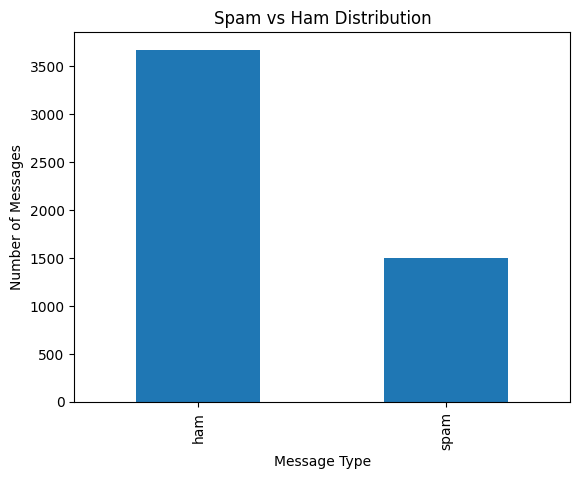

In [ ]:
import matplotlib.pyplot as plt

df['label'].value_counts().plot(kind='bar')

plt.title('Spam vs Ham Distribution')
plt.xlabel('Message Type')
plt.ylabel('Number of Messages')
plt.show()

In [ ]:
print(df.isnull().sum())

Unnamed: 0    0
label         0
text          0
label_num     0
dtype: int64


In [ ]:
# Separate features and target
X = df['text']
y = df['label_num']

print(X.head())
print(y.head())

0    Subject: enron methanol ; meter # : 988291\nth...
1    Subject: hpl nom for january 9 , 2001\n( see a...
2    Subject: neon retreat\nho ho ho , we ' re arou...
3    Subject: photoshop , windows , office . cheap ...
4    Subject: re : indian springs\nthis deal is to ...
Name: text, dtype: object
0    0
1    0
2    0
3    1
4    0
Name: label_num, dtype: int64


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

# Convert text into numerical features
vectorizer = CountVectorizer()

X_vectorized = vectorizer.fit_transform(X)

print(X_vectorized.shape)

(5171, 50447)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_vectorized,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4136, 50447)
Testing data: (1035, 50447)


In [ ]:
from sklearn.naive_bayes import MultinomialNB

# Create the model
model = MultinomialNB()

# Train the model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
# Predict using the testing data
y_pred = model.predict(X_test)

print(y_pred[:10])

[0 0 0 0 0 1 0 0 0 1]


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.978743961352657
Precision: 0.9727891156462585
Recall: 0.9533333333333334
F1 Score: 0.9629629629629629


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=['Ham', 'Spam']
))

              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       735
        Spam       0.97      0.95      0.96       300

    accuracy                           0.98      1035
   macro avg       0.98      0.97      0.97      1035
weighted avg       0.98      0.98      0.98      1035



In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[727   8]
 [ 14 286]]


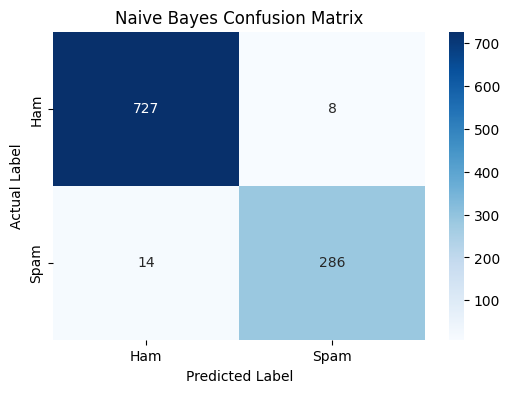

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Naive Bayes Confusion Matrix')

plt.show()

In [ ]:
# Create new messages
new_messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hello, are we meeting tomorrow?",
    "URGENT! You have won cash. Call now!",
    "Please send me the assignment notes."
]

# Convert messages into numerical features
new_messages_vectorized = vectorizer.transform(new_messages)

# Predict the messages
predictions = model.predict(new_messages_vectorized)

# Display results
for message, prediction in zip(new_messages, predictions):
    result = "Spam" if prediction == 1 else "Ham"

    print("Message:", message)
    print("Prediction:", result)
    print("------------------------")

Message: Congratulations! You have won a free prize. Claim now!
Prediction: Spam
------------------------
Message: Hello, are we meeting tomorrow?
Prediction: Ham
------------------------
Message: URGENT! You have won cash. Call now!
Prediction: Spam
------------------------
Message: Please send me the assignment notes.
Prediction: Ham
------------------------


In [ ]:
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score

# Train Bernoulli Naive Bayes
bernoulli_model = BernoulliNB()

bernoulli_model.fit(X_train, y_train)

# Make predictions
bernoulli_pred = bernoulli_model.predict(X_test)

# Compare accuracy
multinomial_accuracy = accuracy_score(y_test, y_pred)

bernoulli_accuracy = accuracy_score(y_test, bernoulli_pred)

print("MultinomialNB Accuracy:", multinomial_accuracy)
print("BernoulliNB Accuracy:", bernoulli_accuracy)

MultinomialNB Accuracy: 0.978743961352657
BernoulliNB Accuracy: 0.8434782608695652


In [ ]:
import pandas as pd
import zipfile
import io
import requests

# Download the UCI SMS dataset
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = requests.get(url)
response.raise_for_status()

# Extract and read the dataset
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    with z.open("SMSSpamCollection") as f:
        df_sms = pd.read_csv(
            f,
            sep="\t",
            header=None,
            names=["label", "text"]
        )

print(df_sms.head())
print("Dataset shape:", df_sms.shape)
print("Columns:", df_sms.columns)


 Original Email Spam Dataset
Accuracy: 0.9768115942028985
Precision: 0.9726027397260274
Recall: 0.9466666666666667
F1-score: 0.9594594594594594

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.98       735
        Spam       0.97      0.95      0.96       300

    accuracy                           0.98      1035
   macro avg       0.98      0.97      0.97      1035
weighted avg       0.98      0.98      0.98      1035


 UCI SMS Spam Dataset
Accuracy: 0.9874439461883409
Precision: 0.9856115107913669
Recall: 0.9194630872483222
F1-score: 0.9513888888888888

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       966
        Spam       0.99      0.92      0.95       149

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



In [ ]:
print(df_sms.info())

print("\nClass distribution:")
print(df_sms["label"].value_counts())

print("\nMissing values:")
print(df_sms.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   text    5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label    0
text     0
dtype: int64


In [ ]:
df_sms["label_num"] = df_sms["label"].map({
    "ham": 0,
    "spam": 1
})

print(df_sms.head())
print(df_sms[["label", "label_num"]].head())

  label                                               text  label_num
0   ham  Go until jurong point, crazy.. Available only ...          0
1   ham                      Ok lar... Joking wif u oni...          0
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...          1
3   ham  U dun say so early hor... U c already then say...          0
4   ham  Nah I don't think he goes to usf, he lives aro...          0
  label  label_num
0   ham          0
1   ham          0
2  spam          1
3   ham          0
4   ham          0


In [ ]:
df_sms.to_csv("uci_sms_spam_collection.csv", index=False)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

def train_and_evaluate(data, dataset_name):

    X = data["text"].fillna("").astype(str)
    y = data["label_num"].astype(int)

    # Split the text before vectorization
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # Convert text into numerical features
    vectorizer = CountVectorizer()

    X_train_vectorized = vectorizer.fit_transform(X_train)
    X_test_vectorized = vectorizer.transform(X_test)

    # Train the same Multinomial Naive Bayes algorithm
    model = MultinomialNB()
    model.fit(X_train_vectorized, y_train)

    # Make predictions
    y_pred = model.predict(X_test_vectorized)

    # Calculate evaluation metrics
    results = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "Confusion Matrix": confusion_matrix(y_test, y_pred)
    }

    print("\n", dataset_name)
    print("Accuracy:", results["Accuracy"])
    print("Precision:", results["Precision"])
    print("Recall:", results["Recall"])
    print("F1-score:", results["F1-score"])

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Ham", "Spam"],
        zero_division=0
    ))

    return model, vectorizer, results, X_test, y_test, y_pred

In [ ]:
# Evaluate original email dataset
original_model, original_vectorizer, original_results, \
original_X_test, original_y_test, original_y_pred = train_and_evaluate(
    df,
    "Original Email Spam Dataset"
)

# Evaluate additional SMS dataset
sms_model, sms_vectorizer, sms_results, \
sms_X_test, sms_y_test, sms_y_pred = train_and_evaluate(
    df_sms,
    "UCI SMS Spam Dataset"
)


 Original Email Spam Dataset
Accuracy: 0.9768115942028985
Precision: 0.9726027397260274
Recall: 0.9466666666666667
F1-score: 0.9594594594594594

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.98       735
        Spam       0.97      0.95      0.96       300

    accuracy                           0.98      1035
   macro avg       0.98      0.97      0.97      1035
weighted avg       0.98      0.98      0.98      1035


 UCI SMS Spam Dataset
Accuracy: 0.9874439461883409
Precision: 0.9856115107913669
Recall: 0.9194630872483222
F1-score: 0.9513888888888888

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       966
        Spam       0.99      0.92      0.95       149

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



In [ ]:
new_sms = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hello, are we meeting tomorrow?",
    "URGENT! You have won cash. Call now!",
    "Please send me the assignment notes.",
    "WIN a free holiday by texting WIN to 80085 now!"
]

# Convert the new messages
new_sms_vectorized = sms_vectorizer.transform(new_sms)

# Predict using the trained SMS model
sms_predictions = sms_model.predict(new_sms_vectorized)

# Display the predictions
for message, prediction in zip(new_sms, sms_predictions):

    result = "Spam" if prediction == 1 else "Ham"

    print("Message:", message)
    print("Prediction:", result)
    print("---------------------------")

Message: Congratulations! You have won a free prize. Claim now!
Prediction: Spam
---------------------------
Message: Hello, are we meeting tomorrow?
Prediction: Ham
---------------------------
Message: URGENT! You have won cash. Call now!
Prediction: Spam
---------------------------
Message: Please send me the assignment notes.
Prediction: Ham
---------------------------
Message: WIN a free holiday by texting WIN to 80085 now!
Prediction: Spam
---------------------------


In [ ]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],

    "Original Email Dataset": [
        original_results["Accuracy"],
        original_results["Precision"],
        original_results["Recall"],
        original_results["F1-score"]
    ],

    "UCI SMS Dataset": [
        sms_results["Accuracy"],
        sms_results["Precision"],
        sms_results["Recall"],
        sms_results["F1-score"]
    ]
})

print(comparison.to_string(index=False))

   Metric  Original Email Dataset  UCI SMS Dataset
 Accuracy                0.976812         0.987444
Precision                0.972603         0.985612
   Recall                0.946667         0.919463
 F1-score                0.959459         0.951389


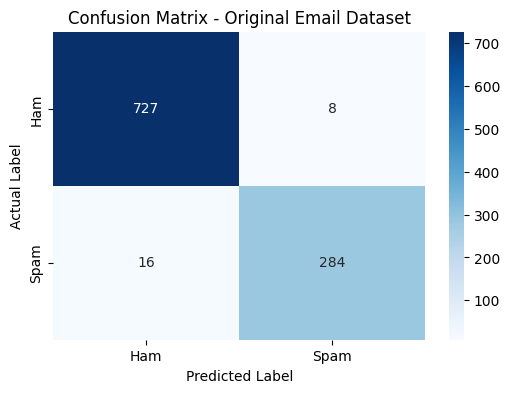

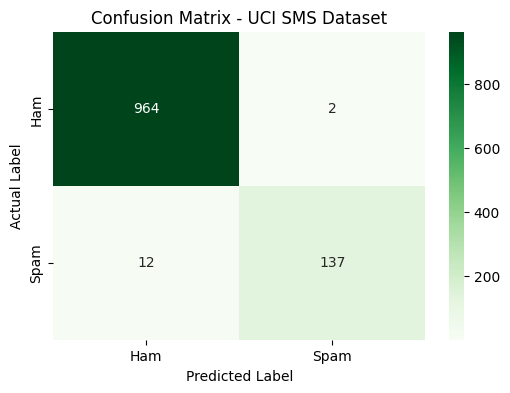

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Original dataset confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    original_results["Confusion Matrix"],
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Confusion Matrix - Original Email Dataset")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


# SMS dataset confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    sms_results["Confusion Matrix"],
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Confusion Matrix - UCI SMS Dataset")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

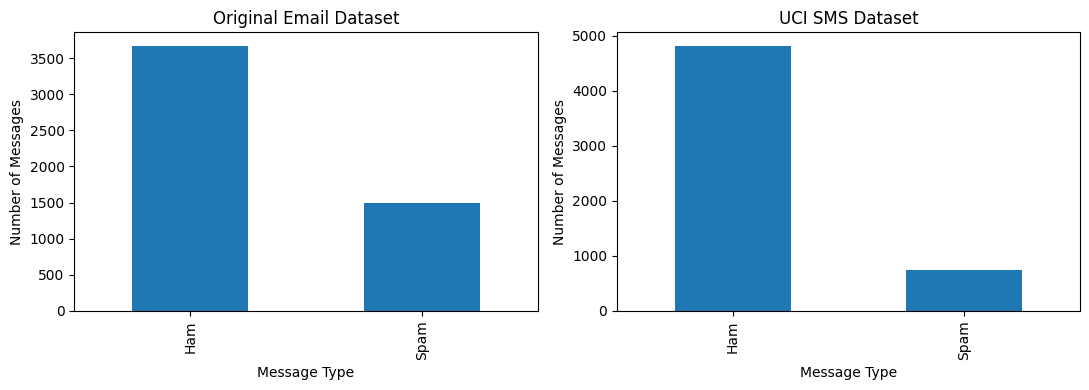

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

df["label_num"].map({0: "Ham", 1: "Spam"}).value_counts().reindex(
    ["Ham", "Spam"]
).plot(kind="bar", ax=axes[0])

axes[0].set_title("Original Email Dataset")
axes[0].set_xlabel("Message Type")
axes[0].set_ylabel("Number of Messages")

df_sms["label"].value_counts().reindex(
    ["ham", "spam"]
).rename(index={"ham": "Ham", "spam": "Spam"}).plot(
    kind="bar", ax=axes[1]
)

axes[1].set_title("UCI SMS Dataset")
axes[1].set_xlabel("Message Type")
axes[1].set_ylabel("Number of Messages")

plt.tight_layout()
plt.show()

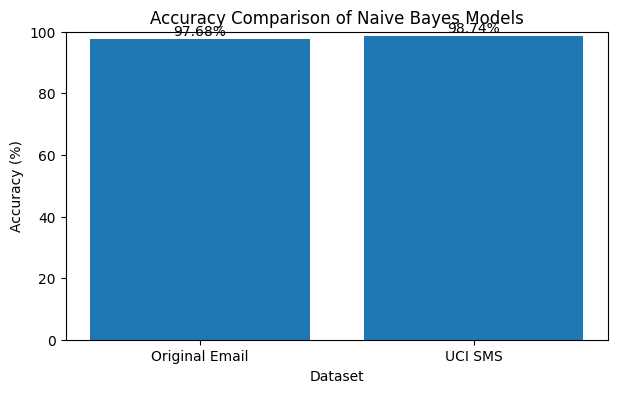

In [ ]:
accuracy_values = [
    original_results["Accuracy"] * 100,
    sms_results["Accuracy"] * 100
]

plt.figure(figsize=(7, 4))

plt.bar(
    ["Original Email", "UCI SMS"],
    accuracy_values
)

plt.title("Accuracy Comparison of Naive Bayes Models")
plt.xlabel("Dataset")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(accuracy_values):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()